# Exploración inicial: dataset de escenas marcianas (5 clases)

Notebook guiado: cada sección indica **objetivo**, **qué calcular**, **pistas** y **preguntas** a responder. El código lo escribes tú. Cuando termines una sección, anota tus conclusiones en la celda *Observaciones*: te servirán para decidir el preprocesado y la nueva partición train/val/test.

**Entorno:** este notebook se ejecuta en **WSL (Ubuntu)** con el kernel del entorno virtual del proyecto (ver README, sección *Entorno*). Usa rutas relativas a la raíz del repo para que funcione igual desde Windows y desde WSL.

## 0. Configuración

- Imports: `pathlib`, `re`, `numpy`, `pandas`, `matplotlib`, `PIL.Image`. Más adelante también `seaborn` e `imagehash`.
- Fija la semilla 42 (`random`, `numpy`), igual que en el artículo.
- Define `ROOT` (raíz del repo) y `DATA = ROOT / "data"`. **Pista:** el notebook vive en la raíz, así que `Path.cwd()` suele bastar. Comprueba con un `assert DATA.exists()`.
- Comprueba que estás en WSL y ves la GPU: `platform.uname()` debería mencionar `microsoft-standard-WSL2`. Cuando instales torch, `torch.cuda.is_available()` debería devolver `True`.

In [1]:
from pathlib import Path
import re 
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image

import seaborn as sns
import imagehash

np.random.seed(42)

ROOT = Path.cwd()
DATA = ROOT/"data"

In [2]:
import torch
torch.cuda.is_available()

True

## 1. Inventario: un DataFrame con una fila por imagen

Todo el análisis posterior sale de esta tabla, así que merece la pena hacerla bien.

Columnas sugeridas:

| columna | cómo obtenerla |
|---|---|
| `path` | `DATA.glob("*/*/*.jpg")` |
| `split_orig` | carpeta abuelo (`train` / `val`) |
| `label` | carpeta padre |
| `sol` | 4 dígitos justo antes de `ML`/`MR` en el nombre |
| `camera` | `ML` o `MR` |
| `width`, `height`, `mode` | `Image.open(p)`; no hace falta cargar los píxeles para leer `.size` |

**Pistas:**
- Hay nombres con prefijo `cr_` (`cr_003_0003ML...`) y sin él (`1000_1000MR...`). Una regex sobre el nombre completo como `r"(\d{4})(M[LR])"` cubre ambos casos. **No** uses el prefijo antes del primer `_`.
- Valida el resultado: ¿hay filas con `sol` nulo? ¿Cuántas imágenes en total? Deberían salir 1000.
- Guarda la tabla en `df` y muéstrala con `df.head()` y `df.describe(include="all")`.

In [3]:
path_list = sorted(list(DATA.glob("*/*/*.jpg")))
filename_list = [p.name for p in DATA.glob("*/*/*.jpg")]
label_list = [str(p.parent).split("/")[8] for p in DATA.glob("*/*/*.jpg")]
split_orig_list = [str(p.parent).split("/")[7] for p in DATA.glob("*/*/*.jpg")]
sol_list = [int( re.compile(r"(\d+)(M[LR])").search(f).group(1)) for f in filename_list]
camera_list = [re.compile(r"(M[LR])").search(f).group(1) for f in filename_list]

In [20]:
width_list = []
height_list = []
mode_list = []
for p in path_list:
    with Image.open(p) as img:
        s = img.size
        width_list.append(s[0])
        height_list.append(s[1])
        mode_list.append(img.mode)


In [21]:
d = {"path": path_list , 
     "filename": filename_list, 
     "label":label_list, 
     "split_orig": split_orig_list, 
     "sol": sol_list, 
     "camera":camera_list, 
     "width":width_list,
     "height":height_list,
     "mode" : mode_list}
df = pd.DataFrame(d)

In [6]:
df.head()

,path,filename,label,split_orig,sol,camera,with,height,mode
0,/mnt/c/Users/Jorge/MarsProject/data/train/arti...,1037_1037MR0045400070204330E01_DXXX.jpg,artifacts,train,1037,MR,560,500,RGB
1,/mnt/c/Users/Jorge/MarsProject/data/train/arti...,1059_1059MR0046570000104690E01_DXXX.jpg,artifacts,train,1059,MR,560,500,RGB
2,/mnt/c/Users/Jorge/MarsProject/data/train/arti...,1060_1060ML0046630000306178E01_DXXX.jpg,artifacts,train,1060,ML,560,500,RGB
3,/mnt/c/Users/Jorge/MarsProject/data/train/arti...,1119_1119MR0049880000601407E01_DXXX.jpg,artifacts,train,1119,MR,560,500,RGB
4,/mnt/c/Users/Jorge/MarsProject/data/train/arti...,1181_1181ML0053500010502582E01_DXXX.jpg,artifacts,train,1181,ML,560,500,RGB


**Observaciones:**

## 2. Distribución de clases

- Gráfico de barras del número de imágenes por clase, **separado por `split_orig`**. Pista: `pd.crosstab(df.label, df.split_orig)` y luego `.plot.bar()`.
- Añade también los porcentajes.

**Preguntas:** ¿están las clases equilibradas? ¿Hace falta ponderar la pérdida o usar un muestreo estratificado? ¿Coincide el reparto con la Tabla 2 del artículo?

In [7]:
pd.crosstab(df.label, df.split_orig)

split_orig,train,val
label,,
artifacts,155,38
invalid,141,35
regolith,182,45
rocks,178,45
rover_tracks,143,38


<Axes: xlabel='label'>

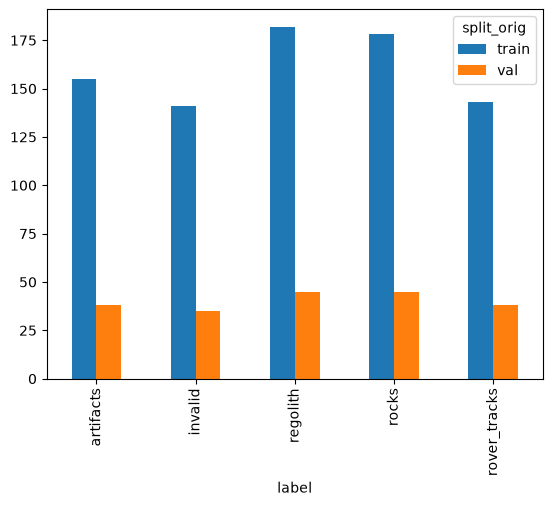

In [8]:
pd.crosstab(df.label, df.split_orig).plot.bar()

**Observaciones:**

## 3. Galería de ejemplos por clase

Haz una cuadrícula de **5 filas (clases) × 6 columnas** con imágenes aleatorias de cada clase, con el nombre de la clase en el eje Y y el sol en el título de cada imagen.

**Pistas:** `fig, axes = plt.subplots(5, 6, figsize=...)`; `df[df.label == c].sample(6, random_state=42)`; `ax.axis("off")`.

**Preguntas:**
- ¿Qué distingue visualmente `regolith`, `rocks` y `rover_tracks`? El artículo dice que son las clases que más se confunden entre sí.
- ¿Encuentras imágenes que tú habrías etiquetado de otra forma? Revisa la regla de prioridad `Invalid > Artifacts > Rover_tracks > Rocks > Regolith`.
- ¿Qué tipos de imagen hay dentro de `invalid`?

**Extra:** repite la galería varias veces con otras semillas o hazla en una función `show_class_grid(df, n=6, seed=...)`. Te servirá en todo el proyecto.

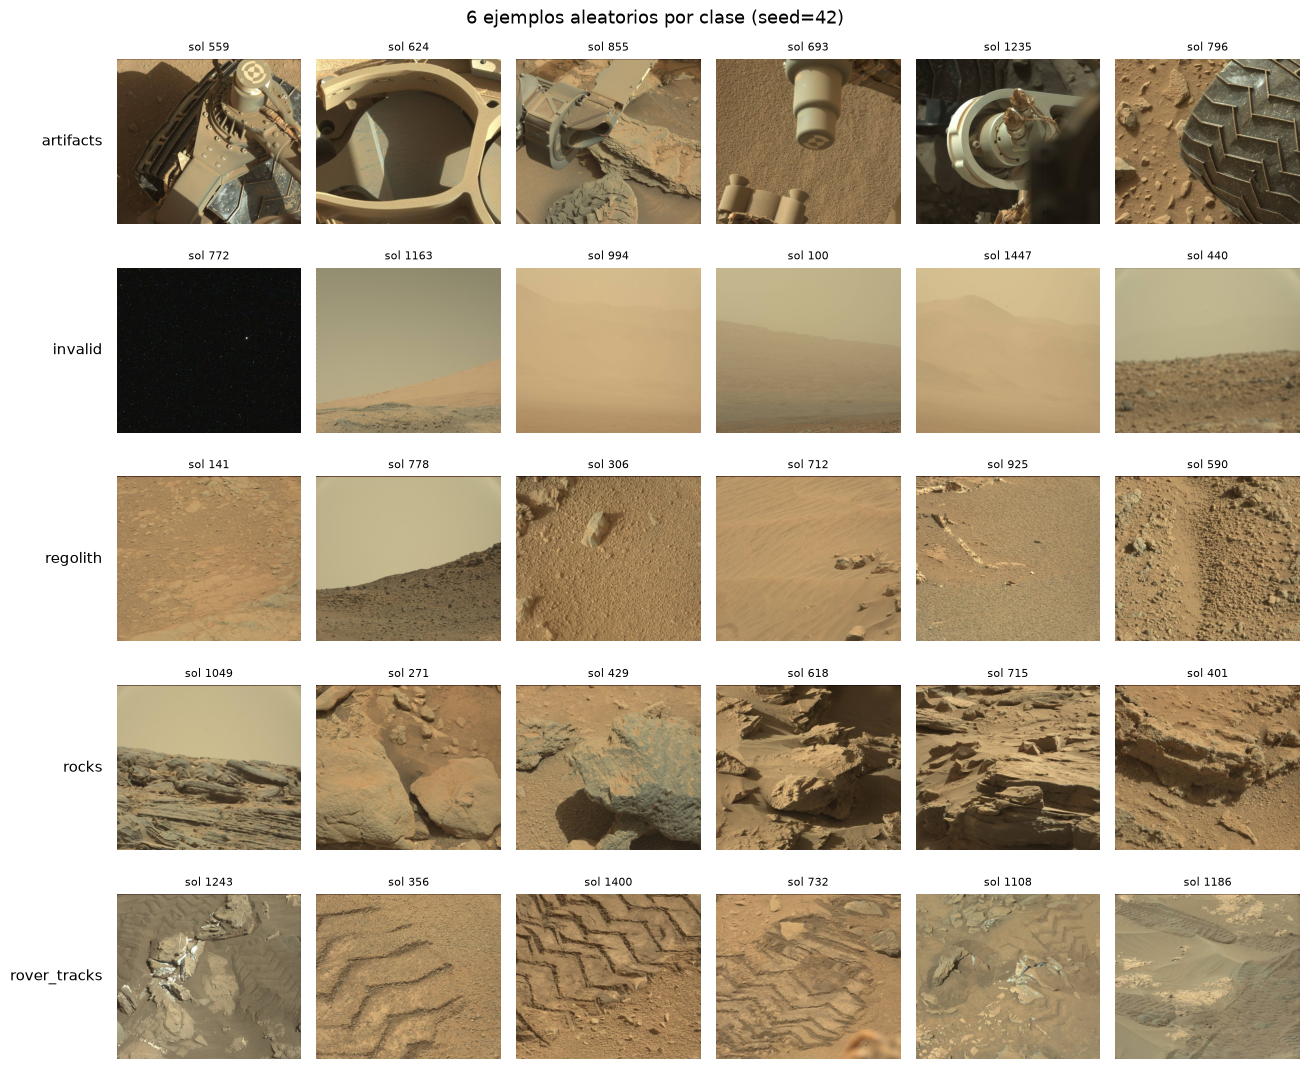

In [9]:
def show_class_grid(df, n=6, seed=42, figsize_per_img=2.2):
    """Muestra n imágenes aleatorias por clase en una cuadrícula (filas = clases)."""
    classes = sorted(df["label"].unique())
    fig, axes = plt.subplots(
        len(classes), n,
        figsize=(n * figsize_per_img, len(classes) * figsize_per_img),
        squeeze=False,
    )

    for row, cls in enumerate(classes):
        subset = df[df["label"] == cls]
        sample = subset.sample(min(n, len(subset)), random_state=seed)

        for col, ax in enumerate(axes[row]):
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

            if col >= len(sample):
                continue
            item = sample.iloc[col]
            with Image.open(item["path"]) as img:
                ax.imshow(img)
            ax.set_title(f"sol {item['sol']}", fontsize=8)

        axes[row][0].set_ylabel(cls, fontsize=11, rotation=0, ha="right", va="center", labelpad=10)

    fig.suptitle(f"{n} ejemplos aleatorios por clase (seed={seed})", fontsize=13)
    fig.tight_layout()
    plt.show()

show_class_grid(df)

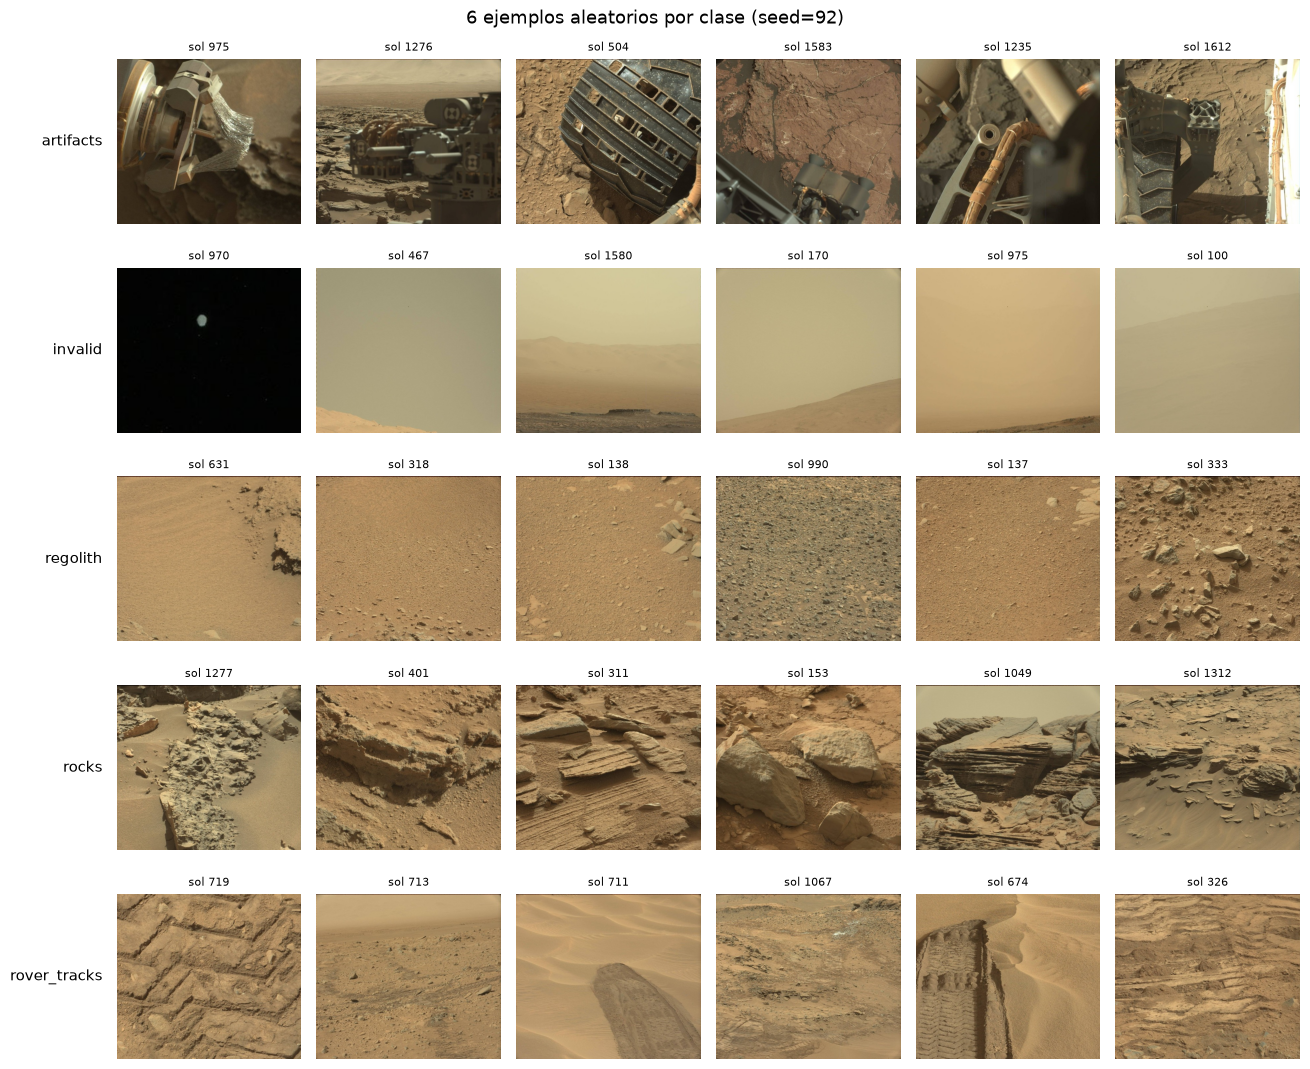

In [11]:
# random images
show_class_grid(df, seed=np.random.randint(0,100) )

**Observaciones:**

## 4. Dimensión temporal: soles

Esta sección es la base para diseñar la nueva partición.

1. Histograma de `sol` para todo el dataset y por clase (`sns.histplot(df, x="sol", hue="label", multiple="stack")` o un panel por clase).
2. Histograma de `sol` coloreado por `split_orig`. ¿Ves que val **no** es "el último 20 % de soles"?
3. Calcula cuántos soles aparecen en train y en val a la vez (intersección de conjuntos). Deberían salir 46.
4. Número de imágenes por sol: `df.groupby("sol").size().describe()`. Recuerda que el artículo fijó un máximo de 2 imágenes por clase y sol; compruébalo con `df.groupby(["sol", "label"]).size().max()`.

**Preguntas:** ¿hay clases concentradas en ciertas épocas de la misión? Por ejemplo, `rover_tracks` podría ser más frecuente en tramos de mucha conducción. Si haces un corte cronológico, ¿alguna clase quedaría casi vacía en test?

<Axes: xlabel='sol', ylabel='Count'>

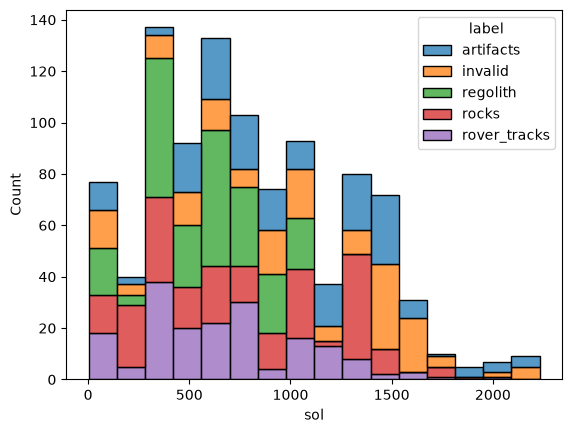

In [12]:
sns.histplot(df,x="sol", hue="label", multiple="stack")

In [13]:
n_sol_intersec = len(set(df[df["split_orig"] == "train"].sol).intersection(set(df[df["split_orig"] == "val"].sol)))

In [14]:
df.groupby("sol").size().describe()

count    557.000000
mean       1.795332
std        1.032448
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        6.000000
dtype: float64

In [15]:
df.groupby(["sol", "label"]).size().max()

np.int64(4)

**Observaciones:**

## 5. Cámara (Mastcam Left vs Right)

- `pd.crosstab(df.label, df.camera, normalize="index")`.
- Muestra una imagen ML y otra MR de la misma clase, una al lado de la otra.

**Pregunta:** ¿el reparto de cámaras está desequilibrado según la clase? Si lo estuviera, el modelo podría aprender un atajo a partir de la cámara (las dos ópticas tienen distinta resolución y campo de visión).

In [16]:
pd.crosstab(df.label, df.camera, normalize="index")

camera,ML,MR
label,,
artifacts,0.880829,0.119171
invalid,0.488636,0.511364
regolith,0.577093,0.422907
rocks,0.165919,0.834081
rover_tracks,0.574586,0.425414


**Observaciones:**

## 6. Tamaño, color y brillo

1. Confirma los tamaños y modos de imagen (deberían ser todas 560×500 RGB). Al redimensionar a 224×224, ¿se deforma la imagen? Plantéate `Resize(256)` + `CenterCrop(224)` frente a `Resize((224, 224))`.
2. Para cada imagen calcula la media y la desviación por canal (R, G, B) y el brillo medio. Añádelos a `df`. **Pista:** `np.asarray(img, dtype=np.float32) / 255`.
3. Dibuja un boxplot o violinplot del brillo medio por clase.
4. Calcula la media y la std RGB **de todo el conjunto de train** y compáralas con las de ImageNet (`[0.485, 0.456, 0.406]` / `[0.229, 0.224, 0.225]`).

**Preguntas:**
- ¿Se puede separar `invalid` solo con el brillo? Si es así, la clase es "fácil" y la accuracy global puede estar inflada.
- ¿Merece la pena normalizar con las estadísticas de Marte en vez de las de ImageNet? Con un backbone preentrenado lo habitual es usar las de ImageNet. Razona por qué.

In [44]:
size_counts = df.groupby(["width", "height", "mode"]).size().rename("n_images")
print(size_counts)

w, h = df["width"].iloc[0], df["height"].iloc[0]
print(f"Proporción ancho/alto: {w / h:.3f}")
print(f"Resize((224, 224)) escala x por {224 / w:.3f} e y por {224 / h:.3f}, así que deforma la imagen")
print(f"Resize(256) + CenterCrop(224) recorta {(1 - 224 / (256 * w / h)) * 100:.1f}% del ancho "
      f"y {(1 - 224 / 256) * 100:.1f}% del alto")

width  height  mode
560    500     RGB     1000
Name: n_images, dtype: int64
Proporción ancho/alto: 1.120
Resize((224, 224)) escala x por 0.400 e y por 0.448, así que deforma la imagen
Resize(256) + CenterCrop(224) recorta 21.9% del ancho y 12.5% del alto


In [45]:
LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)
def image_stats(path):
    with Image.open(path) as img:
        x = np.asarray(img.convert("RGB"))
        media_canal = x.mean(axis=(0,1))
        std_canal = x.std(axis=(0, 1))
        #mean = x.mean()
        return {
        "mean_r": media_canal[0], "mean_g": media_canal[1], "mean_b": media_canal[2],
        "std_r": std_canal[0], "std_g": std_canal[1], "std_b": std_canal[2],
        "brightness": float((x @ LUMA).mean()),
        "contrast": float((x @ LUMA).std()),
    }

In [46]:
df = df.reset_index(drop=True)
stats = pd.DataFrame([image_stats(p) for p in df["path"]])
df = pd.concat([df.drop(columns=stats.columns, errors="ignore"), stats], axis=1)

In [47]:
df.groupby("label")[["brightness", "contrast", "mean_r", "mean_g", "mean_b"]].agg(["mean", "std"]).round(3)

brightness         contrast           mean_r           mean_g  \
                   mean     std     mean     std     mean     std     mean   
label                                                                        
artifacts       107.491  22.702   38.783   9.248  122.265  26.268  105.802   
invalid         143.571  57.199   14.844  11.101  159.124  63.861  142.507   
regolith        139.760  11.976   21.418   7.197  164.387  14.158  135.932   
rocks           125.223  15.532   34.367   8.556  146.103  18.068  122.226   
rover_tracks    136.728  11.783   23.102   7.222  160.897  12.267  132.801   

                       mean_b          
                 std     mean     std  
label                                  
artifacts     22.324   77.443  17.177  
invalid       56.819  108.254  44.252  
regolith      11.924   94.881   9.687  
rocks         15.344   85.887  12.049  
rover_tracks  12.188   93.556  11.660

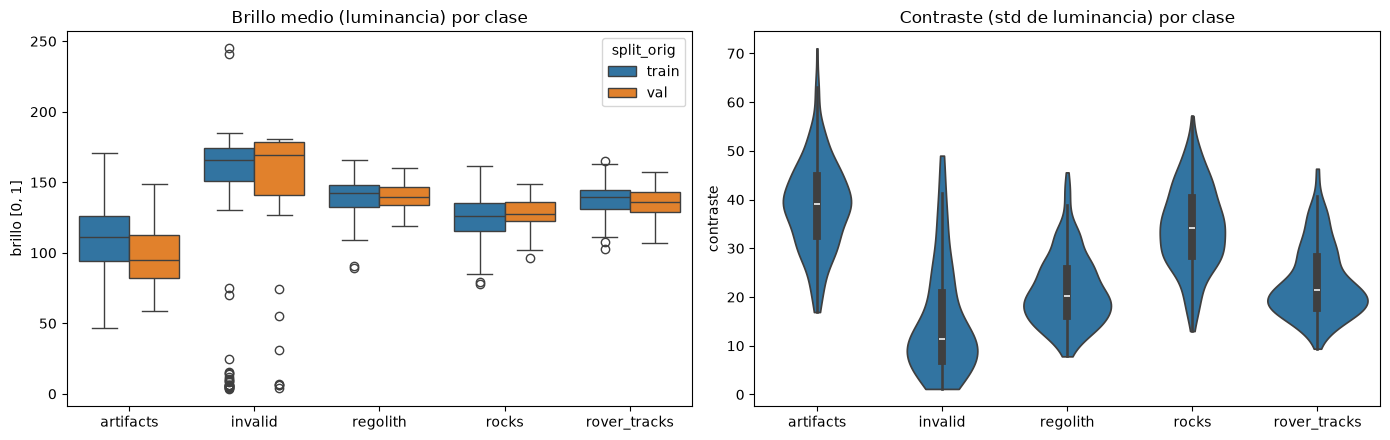

In [48]:
order = sorted(df["label"].unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=df, x="label", y="brightness", hue="split_orig", order=order, ax=axes[0])
axes[0].set_title("Brillo medio (luminancia) por clase")
axes[0].set_xlabel(""); axes[0].set_ylabel("brillo [0, 1]")

sns.violinplot(data=df, x="label", y="contrast", order=order, cut=0, ax=axes[1])
axes[1].set_title("Contraste (std de luminancia) por clase")
axes[1].set_xlabel(""); axes[1].set_ylabel("contraste")

fig.tight_layout()
plt.show()

In [49]:
is_invalid = (df["label"] == "invalid").to_numpy()
b = df["brightness"].to_numpy()
best = max(
    (max(((b < t) == is_invalid).mean(), ((b > t) == is_invalid).mean()), t)
    for t in np.unique(b)
)
print(f"invalid vs resto usando solo el brillo: accuracy {best[0]:.3f} con umbral {best[1]:.3f} "
      f"(base: {1 - is_invalid.mean():.3f})")

invalid vs resto usando solo el brillo: accuracy 0.929 con umbral 159.931 (base: 0.824)


In [52]:
def channel_mean_std(paths):
    """Media y std por canal sobre TODOS los píxeles, con acumuladores (sin cargar todo en memoria)."""
    s = np.zeros(3, dtype=np.float64)
    s2 = np.zeros(3, dtype=np.float64)
    s = np.zeros(3, dtype=np.float64)
    s2 = np.zeros(3, dtype=np.float64)
    n = 0
    for p in paths:
        with Image.open(p) as img:
            x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
        s += x.sum(axis=(0, 1))
        s2 += (x ** 2).sum(axis=(0, 1))
        n += x.shape[0] * x.shape[1]
    mean = s / n
    std = np.sqrt(s2 / n - mean ** 2)
    return mean, std



In [53]:
# PROVISIONAL: split original. Recalcular con split_v1.csv (solo train) en la sección 9.
train_paths = df.loc[df["split_orig"] == "train", "path"]
mars_mean, mars_std = channel_mean_std(train_paths)

# Comprobación: el promedio de las std por imagen sale más bajo que la std global
naive_std = df.loc[df["split_orig"] == "train", ["std_r", "std_g", "std_b"]].mean().to_numpy()

norm_table = pd.DataFrame(
    [mars_mean, mars_std, naive_std, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]],
    index=["Marte mean", "Marte std", "Marte std (promedio ingenuo)", "ImageNet mean", "ImageNet std"],
    columns=["R", "G", "B"],
).round(4)
norm_table

,R,G,B
Marte mean,0.5914,0.5032,0.3623
Marte std,0.1841,0.1657,0.1350
Marte std (promedio ingenuo),29.0921,26.9633,22.6032
ImageNet mean,0.4850,0.4560,0.4060
ImageNet std,0.2290,0.2240,0.2250


**Observaciones:**

## 7. Imagen media por clase

Promedia todas las imágenes de cada clase (redimensionadas, por ejemplo, a 128×128) y muestra las 5 medias en una fila.

**Pregunta:** ¿se ve estructura? Por ejemplo, horizonte o cielo en `invalid` y partes del rover en `artifacts`. Si las medias son muy distintas, el problema tiene sesgos globales fáciles de aprender.

**Observaciones:**

## 8. Duplicados y casi-duplicados (fuga de datos)

Calcula un hash perceptual de cada imagen (`pip install imagehash`; `imagehash.phash(img)`) y busca pares con distancia de Hamming pequeña (`h1 - h2 <= 5`, por ejemplo).

- ¿Hay duplicados dentro de la misma clase? ¿Entre train y val?
- ¿Hay la **misma imagen con etiquetas distintas**? Eso sería ruido de etiquetado.
- Muestra los pares sospechosos uno al lado del otro.

**Pista:** con 1000 imágenes basta con comparar todos los pares por fuerza bruta (unos 500k pares). Convierte los hashes a arrays de bits con `h.hash.flatten()` y compara de forma vectorizada con numpy.

**Observaciones:**

## 9. Diseño de la nueva partición train / val / test

Objetivo: una partición **más realista** que la publicada. Hay que evitar la fuga por sol y reservar un test que no se toque hasta el final.

**Pasos propuestos:**
1. Junta las 1000 imágenes (ignora `split_orig`).
2. **Opción A, cronológica** (simula la operación real: se entrena con el pasado y se evalúa con el futuro). Ordena los soles y corta por **número de imágenes acumuladas** en las fronteras de sol, por ejemplo 70 / 15 / 15.
3. **Opción B, agrupada y estratificada por sol:** `sklearn.model_selection.StratifiedGroupKFold` con `groups=df.sol`. Los soles no se mezclan, pero el reparto no es temporal. Úsala si la opción A deja alguna clase casi vacía en test.
4. Comprueba lo que elijas con:
   - `assert` de que ningún sol aparece en dos splits;
   - una tabla `crosstab(label, split)` para que todas las clases tengan muestras suficientes en val y test.
5. **Restricción por el few-shot:** para episodios 5-way 5-shot con 15 imágenes de query, cada clase necesita **≥ 20 imágenes** en el split donde se muestreen los episodios de evaluación. Compruébalo.
6. Guarda la partición en `splits/split_v1.csv` (`path, label, sol, split`) para que todos los experimentos usen exactamente la misma.

**Preguntas:** ¿qué opción eliges y por qué? ¿Cuánto cambia el reparto de clases entre splits?

In [64]:
from sklearn.model_selection import StratifiedGroupKFold

SPLIT_SEED = 42
N_FOLDS = 10
TEST_FOLDS = {0}        # 1/10 = 10 %
VAL_FOLDS = {1, 2}      # 2/10 = 20 %  (el resto, 7/10 = 70 %, es train)

# Orden fijo: glob() no garantiza el orden y entonces la partición no sería reproducible
base = df[["path", "label", "sol", "camera", "split_orig"]].sort_values("path").reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SPLIT_SEED)
fold = np.full(len(base), -1)
for k, (_, idx) in enumerate(sgkf.split(base, y=base["label"], groups=base["sol"])):
    fold[idx] = k
assert (fold >= 0).all()

base["fold"] = fold
base["split"] = np.select(
    [base["fold"].isin(TEST_FOLDS), base["fold"].isin(VAL_FOLDS)],
    ["test", "val"],
    default="train",
)

In [65]:
sols = {s: set(base.loc[base["split"] == s, "sol"]) for s in ["train", "val", "test"]}
assert not (sols["train"] & sols["val"]), "fuga train/val"
assert not (sols["train"] & sols["test"]), "fuga train/test"
assert not (sols["val"] & sols["test"]), "fuga val/test"
print("Soles por split:", {s: len(v) for s, v in sols.items()}, "-> sin solapamiento ")

Soles por split: {'train': 388, 'val': 114, 'test': 55} -> sin solapamiento 


In [66]:
order = ["train", "val", "test"]
counts = pd.crosstab(base["label"], base["split"], margins=True)[order + ["All"]]
pct_split = (base["split"].value_counts(normalize=True)[order] * 100).round(1)
print("\n% por split:", pct_split.to_dict())
display(counts)
display((pd.crosstab(base["label"], base["split"], normalize="columns")[order] * 100).round(1))


% por split: {'train': 69.9, 'val': 20.1, 'test': 10.0}


split,train,val,test,All
label,,,,
artifacts,135,38,20,193
invalid,122,36,18,176
regolith,159,46,22,227
rocks,156,45,22,223
rover_tracks,127,36,18,181
All,699,201,100,1000


split,train,val,test
label,,,
artifacts,19.3,18.9,20.0
invalid,17.5,17.9,18.0
regolith,22.7,22.9,22.0
rocks,22.3,22.4,22.0
rover_tracks,18.2,17.9,18.0


**Observaciones / decisión final:**

In [67]:
SPLITS_DIR = ROOT / "splits"
SPLITS_DIR.mkdir(exist_ok=True)

out = base[["path", "label", "sol", "camera", "split_orig", "split"]].copy()
out["path"] = out["path"].map(lambda p: Path(p).relative_to(ROOT).as_posix())   # ruta relativa, válida en Windows y WSL
out.to_csv(SPLITS_DIR / "split_v1.csv", index=False)
print("Guardado:", SPLITS_DIR / "split_v1.csv", out.shape)

# Comprobación de que se recarga igual
check = pd.read_csv(SPLITS_DIR / "split_v1.csv")
assert (check["split"].value_counts() == out["split"].value_counts()).all()

Guardado: /mnt/c/Users/Jorge/MarsProject/splits/split_v1.csv (1000, 6)


## 10. (Opcional) Vista previa de las aumentaciones

Cuando tengas torch y torchvision instalados en WSL, aplica a una misma imagen las aumentaciones del artículo y muéstralas en una cuadrícula: `RandomHorizontalFlip`, `ColorJitter(brightness=..., contrast=...)` y, según la Fig. 2, recorte y ruido gaussiano.

**Pregunta:** ¿alguna aumentación cambia la clase de la imagen? Por ejemplo, oscurecer demasiado una imagen de `regolith` puede hacer que parezca `invalid`.

In [58]:
import torch
from torchvision.transforms import v2 as T

torch.manual_seed(42)

# Hiperparámetros de aumentación (no especificados en el artículo -> decisión propia)
BRIGHTNESS = 0.3
CONTRAST = 0.3
CROP_SCALE = (0.7, 1.0)
NOISE_STD = 0.03

class AddGaussianNoise(torch.nn.Module):
    """Ruido gaussiano sobre un tensor float en [0, 1]. Se recorta para seguir en [0, 1]."""
    def __init__(self, std=0.03, p=0.5):
        super().__init__()
        self.std, self.p = std, p
    def forward(self, x):
        if torch.rand(1).item() < self.p:
            x = (x + torch.randn_like(x) * self.std).clamp(0, 1)
        return x

In [59]:
to_tensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
base_resize = T.Resize((224, 224), antialias=True)

In [63]:
# Cada aumentación por separado (p=1 para ver siempre su efecto)
single_augs = {
    "original":           T.Identity(),
    "flip horizontal":    T.RandomHorizontalFlip(p=1.0),
    f"brillo ±{BRIGHTNESS}":  T.ColorJitter(brightness=BRIGHTNESS),
    f"contraste ±{CONTRAST}": T.ColorJitter(contrast=CONTRAST),
    f"recorte {CROP_SCALE}":  T.RandomResizedCrop(224, scale=CROP_SCALE, ratio=(1.0, 1.25), antialias=True),
    f"ruido σ={NOISE_STD}":   AddGaussianNoise(std=NOISE_STD, p=1.0),
    
}
train_aug = T.Compose([
    T.RandomResizedCrop(224, scale=CROP_SCALE, ratio=(1.0, 1.25), antialias=True),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=BRIGHTNESS, contrast=CONTRAST),
    AddGaussianNoise(std=NOISE_STD, p=0.5),
])

def show(ax, x, title):
    ax.imshow(x.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

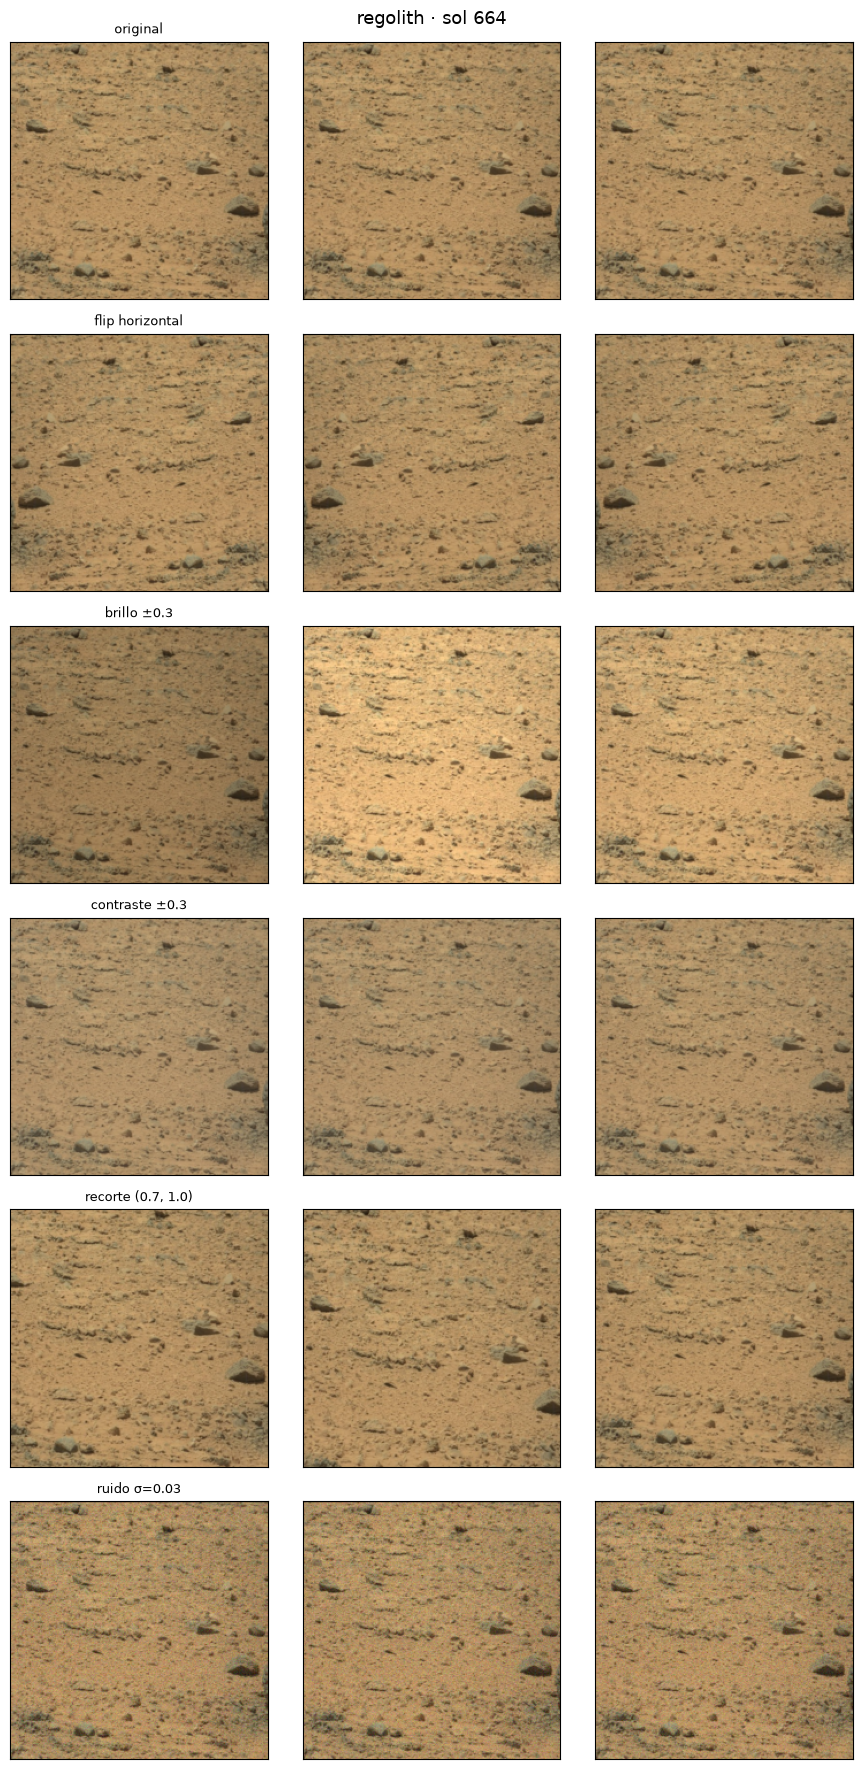

In [62]:

item = base[(base["split"] == "train") & (base["label"] == "regolith")].sample(1, random_state=42).iloc[0]
with Image.open(item["path"]) as img:
    x0 = to_tensor(img.convert("RGB"))

n_rep = 3
fig, axes = plt.subplots(len(single_augs), n_rep, figsize=(3 * n_rep, 3 * len(single_augs)))
for i, (name, aug) in enumerate(single_augs.items()):
    for j in range(n_rep):
        x = aug(x0) if name.startswith("recorte") else aug(base_resize(x0))
        show(axes[i, j], x, name if j == 0 else "")
fig.suptitle(f"{item['label']} · sol {item['sol']}", fontsize=13)
fig.tight_layout()
plt.show()

## Resumen de conclusiones

Enumera aquí las 5–10 conclusiones clave y las decisiones que tomas para el preprocesado y la partición. Después pásalas al README.